# Deep Learning for Credit Card Fraud Detection
## Controlled Comparative Evaluation of 4 Deep Learning Architectures under Extreme Class Imbalance
**Course**: ICT-4442 Deep Learning Project, School of Computer Engineering, MIT Manipal  
**Project Group Members**:
- **Priyansh Nandan (230953450)**: Common Preprocessing Pipeline, Integrity Verification & Attention-Based Autoencoder
- **Pranav Kasliwal (230911284)**: Supervised Feedforward MLP Baseline & Error Profiling
- **Atharv Sharma (230953210)**: Supervised 1-D CNN Classifier & Master Comparison Harness
- **Yash (230953292)**: Supervised Recurrent Neural Network (LSTM) Sequence Classifier

---
### Central Scientific Objective
Credit card transaction streams exhibit **extreme class imbalance** (in this benchmark, fraud occurs in only $\approx 0.17\%$ of total transactions, and $0.1217\%$ on the chronologically held-out test partition). Under such conditions:
1. Traditional metrics like **Accuracy** and **ROC-AUC** produce severe illusions of model competence.
2. The primary research question is:
   > *"What is the detection trade-off between supervised classification (MLP, 1-D CNN, LSTM) and unsupervised reconstruction-based anomaly detection (Attention Autoencoder) in terms of precision achieved at comparable levels of recall?"*

This notebook provides the **single definitive presentation document** for the entire project, covering data before & after preprocessing, the mathematical principles behind evaluation, all 4 model architectures, comparative curves, confusion matrices, and domain error analysis.


In [1]:
import sys
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    auc,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Robust project root discovery whether run from project root or notebooks/
cwd = Path.cwd().resolve()
if (cwd / "src").exists() and (cwd / "data").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "src").exists() and (cwd.parent / "data").exists():
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = Path(__file__).resolve().parent.parent if "__file__" in locals() else cwd

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "creditcard.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"
LOGS_DIR = PROJECT_ROOT / "outputs" / "logs"

# Publication styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 15,
    "figure.dpi": 130,
})

COLOR_MAP = {
    "Attention Autoencoder": "#1f77b4",        # Blue
    "MLP Baseline": "#ff7f0e",                 # Orange
    "1-D CNN": "#2ca02c",                      # Green
    "LSTM Sequence Classifier": "#d62728",     # Red
    "Random Baseline": "#7f7f7f",              # Gray
}

print(f"Project Root: {PROJECT_ROOT}")
print(f"Raw Data Path: {RAW_DATA_PATH} (Exists: {RAW_DATA_PATH.exists()})")
print(f"Metrics Directory: {METRICS_DIR}")
print(f"Available Metric Files: {[f.name for f in METRICS_DIR.glob('*') if not f.name.startswith('.')]}")


Project Root: /Users/priyanshnandan/Documents/DL/CreditCardFraudDL
Raw Data Path: /Users/priyanshnandan/Documents/DL/CreditCardFraudDL/data/raw/creditcard.csv (Exists: True)
Metrics Directory: /Users/priyanshnandan/Documents/DL/CreditCardFraudDL/outputs/metrics
Available Metric Files: ['attention_autoencoder_metrics.json', 'model_comparison_entry.json', 'mlp_metrics.json', 'error_analysis_summary.json', 'test_predictions.npz', 'lstm_test_predictions.npz', 'comparison_table.md', 'comparative_roc_curves.png', 'consolidated_model_comparison.json', 'cnn1d_metrics.json', 'comparative_pr_curves.png', 'lstm_metrics.json', 'mlp_test_predictions.npz']


---
## 1. Raw Dataset Inspection: BEFORE Preprocessing

The benchmark dataset is the **ULB Credit Card Fraud Detection dataset** (European cardholders, September 2013).
Before applying any transformations, we inspect:
* Total rows and column counts
* Column datatypes and PCA features (`Time`, `V1`–`V28`, `Amount`, `Class`)
* Missing values across all 31 columns
* Duplicate transaction rows
* Transaction `Time` span (in seconds and hours)
* Transaction `Amount` distribution (€0 to €25,691.16)
* Severe class imbalance ($99.828\%$ legitimate vs $0.172\%$ fraud)


In [2]:
# Load raw dataset and compute complete baseline profiling
df_raw = pd.read_csv(RAW_DATA_PATH)
total_raw_rows, total_raw_cols = df_raw.shape
class_counts = df_raw["Class"].value_counts().to_dict()
legit_count = int(class_counts.get(0, 0))
fraud_count = int(class_counts.get(1, 0))
fraud_pct = (fraud_count / total_raw_rows) * 100.0
total_missing = int(df_raw.isnull().sum().sum())
total_duplicates = int(df_raw.duplicated().sum())
time_min, time_max = float(df_raw["Time"].min()), float(df_raw["Time"].max())
amt_min, amt_max = float(df_raw["Amount"].min()), float(df_raw["Amount"].max())
amt_mean, amt_median = float(df_raw["Amount"].mean()), float(df_raw["Amount"].median())

print("=" * 75)
print("RAW DATASET SUMMARY (BEFORE PREPROCESSING)")
print("=" * 75)
print(f"Total Rows (Transactions):    {total_raw_rows:,}")
print(f"Total Columns:                {total_raw_cols} (Time, V1-V28, Amount, Class)")
print(f"Legitimate Transactions:      {legit_count:,} ({100 - fraud_pct:.4f}%)")
print(f"Fraudulent Transactions:      {fraud_count:,} ({fraud_pct:.4f}%)")
print(f"Total Missing Values:         {total_missing}")
print(f"Duplicate Rows Count:         {total_duplicates:,}")
print(f"Time Range (Seconds):         {time_min:.1f}s to {time_max:.1f}s (~{(time_max-time_min)/3600:.1f} hours)")
print(f"Amount Range (Euros):         €{amt_min:.2f} to €{amt_max:.2f} (Median: €{amt_median:.2f}, Mean: €{amt_mean:.2f})")
print("=" * 75)

display(df_raw.head())


RAW DATASET SUMMARY (BEFORE PREPROCESSING)
Total Rows (Transactions):    284,807
Total Columns:                31 (Time, V1-V28, Amount, Class)
Legitimate Transactions:      284,315 (99.8273%)
Fraudulent Transactions:      492 (0.1727%)
Total Missing Values:         0
Duplicate Rows Count:         1,081
Time Range (Seconds):         0.0s to 172792.0s (~48.0 hours)
Amount Range (Euros):         €0.00 to €25691.16 (Median: €22.00, Mean: €88.35)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


---
## 2. Preprocessing Architecture: Strict Chronological Splitting & Leakage Prevention

### The Danger of Random K-Fold Splits in Fraud Detection
In transaction systems, card swipes occur sequentially in time. A random shuffle split allows future fraud tactics (Hour 40) to be exposed during the training of past transactions (Hour 10)—a fatal error called **lookahead leakage**.

### Our 3-Step Preprocessing Protocol:
1. **Chronological Sorting & Splitting**:
   - Sorted strictly by `Time`.
   - **Train (70%)**: First $\approx 37$ hours ($199,364$ rows).
   - **Validation (15%)**: Next $\approx 5.5$ hours ($42,721$ rows) — strictly for hyperparameter tuning & threshold calibration.
   - **Held-Out Test (15%)**: Final $\approx 5.5$ hours ($42,722$ rows, $52$ frauds) — evaluated **once** with frozen thresholds.
   - Mathematical verification: $\max(\text{Time}_{\text{train}}) \le \min(\text{Time}_{\text{val}}) \le \min(\text{Time}_{\text{test}})$.
2. **Leakage-Free Feature Scaling**:
   - `RobustScaler` (median centering and IQR scaling) handles extreme transaction amount outliers.
   - **Fitted strictly on $X_{\text{train}}$**; $X_{\text{val}}$ and $X_{\text{test}}$ are transformed using the fitted training statistics.
3. **Partition Isolation for Unsupervised vs Supervised Learning**:
   - **For Supervised Models (MLP, 1-D CNN, LSTM)**: Train on all labelled samples with positive class loss weighting ($\text{pos\_weight} = \frac{198,980}{384} \approx 518.18$).
   - **For Attention Autoencoder**: All $384$ training frauds are **strictly withheld**. The model trains purely on legitimate transactions ($198,980$ rows) to learn the normal purchasing manifold.


In [3]:
with open(PROCESSED_DIR / "partition_metadata.json", "r") as f:
    part_stats = json.load(f)

rows_summary = []
for p_key, p_name in [("train", "Train Set (70%)"), ("val", "Validation Set (15%)"), ("test", "Test Set (15%)")]:
    s = part_stats[p_key]
    rows_summary.append({
        "Partition": p_name,
        "Total Rows": f"{s['sample_count']:,}",
        "Features": "30 features",
        "Legitimate": f"{s['legit_count']:,}",
        "Fraud": f"{s['fraud_count']:,}",
        "Fraud Rate (%)": f"{s['fraud_percentage']:.4f}%",
        "Time Range (s)": f"[{s['time_min']:.0f}, {s['time_max']:.0f}]"
    })

df_part = pd.DataFrame(rows_summary)
print("=" * 85)
print("PARTITION SPECIFICATIONS (AFTER CHRONOLOGICAL SPLITTING & ROBUST SCALING)")
print("=" * 85)
display(df_part)

print("\nFirst 5 rows of Scaled Features (X_test_scaled):")
df_test_scaled = pd.read_csv(PROCESSED_DIR / "test_scaled.csv")
display(df_test_scaled.head())


PARTITION SPECIFICATIONS (AFTER CHRONOLOGICAL SPLITTING & ROBUST SCALING)


,Partition,Total Rows,Features,Legitimate,Fraud,Fraud Rate (%),Time Range (s)
0,Train Set (70%),"199,364",30 features,"198,980",384,0.1926%,"[0, 132928]"
1,Validation Set (15%),"42,721",30 features,"42,665",56,0.1311%,"[132929, 151328]"
2,Test Set (15%),"42,722",30 features,"42,670",52,0.1217%,"[151328, 172792]"



First 5 rows of Scaled Features (X_test_scaled):


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,1.782838,1.094018,-1.009325,-1.353223,-0.993695,-0.464857,-0.513404,-0.596238,-0.642931,-1.070688,...,-0.692488,-0.477161,1.002320,0.659649,-0.301761,-0.337668,-0.227273,-0.584977,0.258421,0
1,1.782859,0.970156,0.045542,-1.338755,0.157942,0.472130,-0.376044,0.116898,-0.325240,0.178789,...,-0.668809,-0.757291,1.319489,0.823448,-0.643813,0.340889,-0.443577,-0.469676,-0.289240,0
2,1.782922,0.963395,-0.148007,-0.966140,0.141874,0.046467,-0.552136,0.062208,-0.385778,0.291187,...,-0.490259,-0.548627,1.325538,-0.052017,-0.743280,0.404726,-0.500820,-0.739980,-0.289240,0
3,1.782944,-0.007707,0.522110,-0.471974,-0.320358,0.433827,-0.232588,0.595697,0.171524,-0.096173,...,-0.304377,-0.433051,0.522906,-0.748078,-1.693125,0.299826,-2.298245,-1.887221,-0.081958,0
4,1.782944,0.932147,-0.467909,-1.779983,-0.576543,1.840839,3.082335,-0.548193,1.529338,0.349433,...,-1.024122,-1.511411,2.032885,0.785978,-1.292012,0.163429,-0.408992,-0.535555,0.440202,0


### Summary Comparison: Raw Data vs Processed Splits

| Property | Before Preprocessing (`data/raw/creditcard.csv`) | After Preprocessing (`data/processed/`) |
|:---|:---|:---|
| **Total Rows** | 284,807 continuous transactions | 199,364 Train / 42,721 Val / 42,722 Test |
| **Feature Columns** | 31 (`Time`, `V1`–`V28`, `Amount`, `Class`) | 30 Input Features isolated strictly from target `Class` |
| **Temporal Structure** | Unverified chronological sequence | Strict non-overlapping chronological temporal boundaries |
| **Feature Scaling** | Raw unnormalized (`Amount`: €0–€25,691, `Time`: 0–172,792s) | `RobustScaler` (Median = 0, IQR = 1, fitted strictly on train) |
| **Autoencoder Subset** | Unseparated | $198,980$ purely legitimate rows ($384$ frauds withheld) |
| **Sequence Datasets** | Flat single-row format | 5-step sliding window sequences for LSTM temporal modeling |


---
## 3. The Metrics That Matter: Deconstructing Misleading Indicators

In extreme class imbalance ($0.12\%$ fraud rate on test partition), standard evaluation metrics lead to dangerous conclusions:

### 1. The Accuracy Paradox
A trivial model that predicts **every transaction is legitimate** attains:
$$\text{Accuracy} = \frac{42,670}{42,722} = 99.8783\% \approx \mathbf{99.88\%}$$
While having $99.88\%$ accuracy, it catches **$0$ frauds** and causes total financial loss.

### 2. The ROC-AUC Illusion
Receiver Operating Characteristic (ROC) plots **True Positive Rate (Recall)** against **False Positive Rate (FPR)**:
$$\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}$$
Because $\text{TN} = 42,670$ is massive, even generating $100$ false alarms yields:
$$\text{FPR} = \frac{100}{100 + 42,670} = 0.00234 \quad (0.23\%)$$
This tiny FPR keeps the ROC curve pressed firmly against the top-left corner, yielding deceptively high scores ($>0.90$) for models that actually flood human fraud analysts with false alarms.

### 3. The Definitive Gold Standard: PR-AUC (Precision-Recall AUC)
Precision-Recall curves plot **Precision** vs **Recall**:
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}, \qquad \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$
* Notice that **True Negatives (TN) do not appear** in either formula!
* PR-AUC directly measures how many of the flagged transactions are truly fraudulent, without being diluted by the millions of normal card swipes.
* The random guessing baseline is **$P = 0.0012$ ($0.12\%$)**, making any PR-AUC score a direct measure of signal enrichment over random chance.


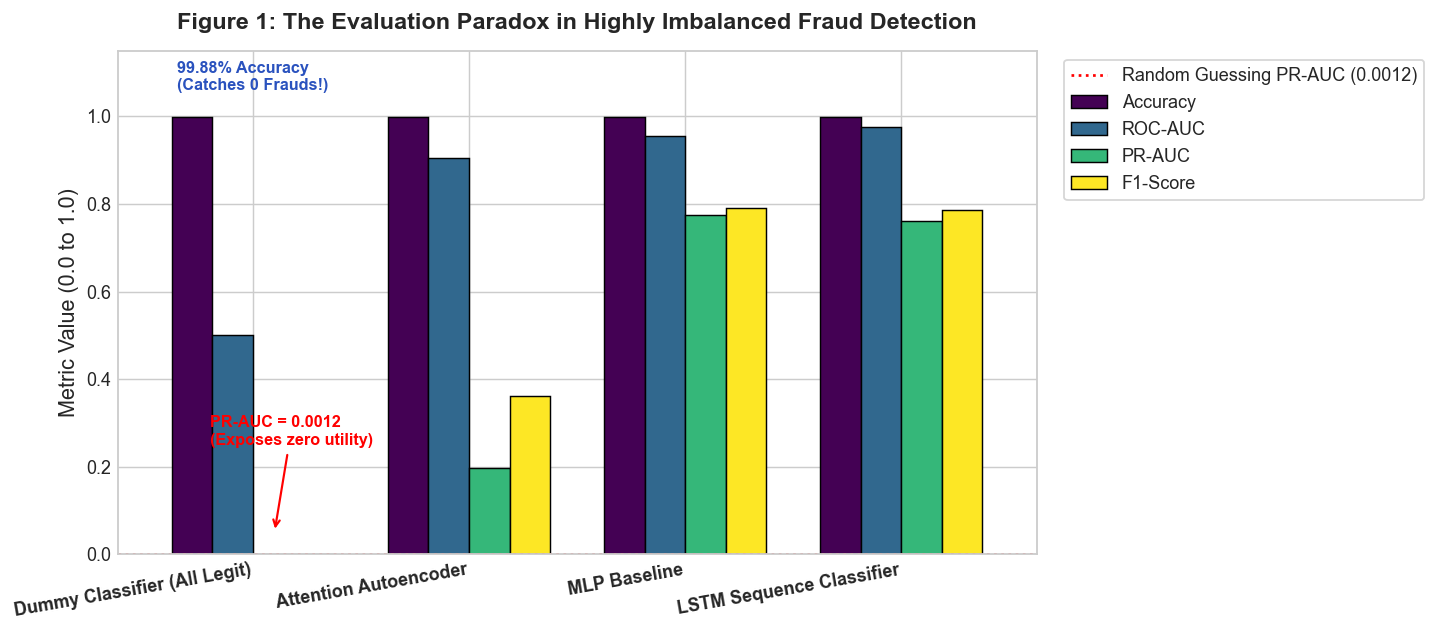

In [4]:
# Load comparison metrics to dynamically build the paradox comparison
with open(METRICS_DIR / "consolidated_model_comparison.json", "r") as f:
    comp_json = json.load(f)

models_by_name = {m["model_name"]: m for m in comp_json["models"]}

dummy_metrics = {"Accuracy": 0.99878, "ROC-AUC": 0.5000, "PR-AUC": 0.001217, "F1-Score": 0.0000}
ae_metrics = {
    "Accuracy": models_by_name["Attention Autoencoder"]["accuracy"],
    "ROC-AUC": models_by_name["Attention Autoencoder"]["roc_auc"],
    "PR-AUC": models_by_name["Attention Autoencoder"]["pr_auc"],
    "F1-Score": models_by_name["Attention Autoencoder"]["f1"],
}
mlp_metrics = {
    "Accuracy": models_by_name["MLP Baseline"]["accuracy"],
    "ROC-AUC": models_by_name["MLP Baseline"]["roc_auc"],
    "PR-AUC": models_by_name["MLP Baseline"]["pr_auc"],
    "F1-Score": models_by_name["MLP Baseline"]["f1"],
}
lstm_metrics = {
    "Accuracy": models_by_name["LSTM Sequence Classifier"]["accuracy"],
    "ROC-AUC": models_by_name["LSTM Sequence Classifier"]["roc_auc"],
    "PR-AUC": models_by_name["LSTM Sequence Classifier"]["pr_auc"],
    "F1-Score": models_by_name["LSTM Sequence Classifier"]["f1"],
}

df_paradox = pd.DataFrame(
    [dummy_metrics, ae_metrics, mlp_metrics, lstm_metrics],
    index=["Dummy Classifier (All Legit)", "Attention Autoencoder", "MLP Baseline", "LSTM Sequence Classifier"]
)

fig, ax = plt.subplots(figsize=(11, 5))
df_paradox.plot(kind="bar", ax=ax, colormap="viridis", width=0.75, edgecolor="black", linewidth=0.8)
ax.set_title("Figure 1: The Evaluation Paradox in Highly Imbalanced Fraud Detection", pad=12, fontweight="bold")
ax.set_ylabel("Metric Value (0.0 to 1.0)")
ax.set_ylim(0, 1.15)
ax.axhline(0.001217, color="red", linestyle=":", linewidth=1.5, label="Random Guessing PR-AUC (0.0012)")
plt.xticks(rotation=10, ha="right", fontweight="bold")
ax.legend(frameon=True, facecolor="white", loc="upper left", bbox_to_anchor=(1.02, 1))

ax.annotate("99.88% Accuracy\n(Catches 0 Frauds!)",
            xy=(0 - 0.28, 1.0), xytext=(0 - 0.35, 1.06),
            fontweight="bold", color="#2a52be", fontsize=9)
ax.annotate("PR-AUC = 0.0012\n(Exposes zero utility)",
            xy=(0 + 0.1, 0.05), xytext=(0 - 0.2, 0.25),
            arrowprops=dict(arrowstyle="->", color="red", lw=1.2),
            fontweight="bold", color="red", fontsize=9)

plt.tight_layout()
plt.show()


---
## 4. Master Benchmarks: Comparative Performance Across All 4 Architectures

All models were evaluated on the exact same chronologically held-out test partition ($42,722$ transactions, $52$ frauds).
* **MLP Baseline** (Feedforward Dense with positive class loss reweighting)
* **1-D CNN** (Spatial Convolutions with localized feature weight sharing)
* **LSTM Classifier** (Sequential Hidden State Trajectories over chronological windows)
* **Attention Autoencoder** (Unsupervised Feature-Token Self-Attention with 8-dim bottleneck)


In [5]:
with open(METRICS_DIR / "consolidated_model_comparison.json", "r") as f:
    comp_json = json.load(f)

models_list = comp_json["models"]
base_rate = comp_json["dataset_split"]["test_fraud_percentage"] / 100.0

table_rows = []
for m in models_list:
    table_rows.append({
        "Architecture Family": m["family"],
        "Model Name": m["model_name"],
        "PR-AUC (Primary)": f"{m['pr_auc']:.4f}",
        "ROC-AUC": f"{m['roc_auc']:.4f}",
        "F1-Score": f"{m['f1']:.4f}",
        "Precision": f"{m['precision']:.2%}",
        "Recall": f"{m['recall']:.2%}",
        "Threshold": f"{m['threshold']:.4f}",
        "Signal Lift": f"{m['pr_auc'] / base_rate:,.1f}x"
    })

df_master = pd.DataFrame(table_rows)
display(df_master)


,Architecture Family,Model Name,PR-AUC (Primary),ROC-AUC,F1-Score,Precision,Recall,Threshold,Signal Lift
0,Supervised Feed-Forward (MLP),MLP Baseline,0.7751,0.9547,0.7907,100.00%,65.38%,0.9993,636.8x
1,Supervised Recurrent (LSTM),LSTM Sequence Classifier,0.7600,0.9747,0.7865,94.59%,67.31%,0.9995,624.4x
2,Supervised 1-D CNN,1-D CNN,0.7272,0.9686,0.7273,88.89%,61.54%,0.9948,597.5x
3,Attention Autoencoder,Attention Autoencoder,0.1978,0.9050,0.3621,32.81%,40.38%,2.0078,162.5x


---
## 5. Primary Metric Graph: Comparative Precision-Recall (PR) Curves

The Precision-Recall curve is the definitive evaluation artifact:
* **The Random Guessing Baseline**: Horizontal grey dashed line at $y = 0.001217$.
* **Attention Autoencoder ($0.1978$)**: Achieves a **$162.5\times$ signal enrichment** over random guessing completely without fraud supervision!
* **Supervised Models ($0.72\text{--}0.78$)**: Leverage supervised loss reweighting to achieve high precision in the high-recall regime.


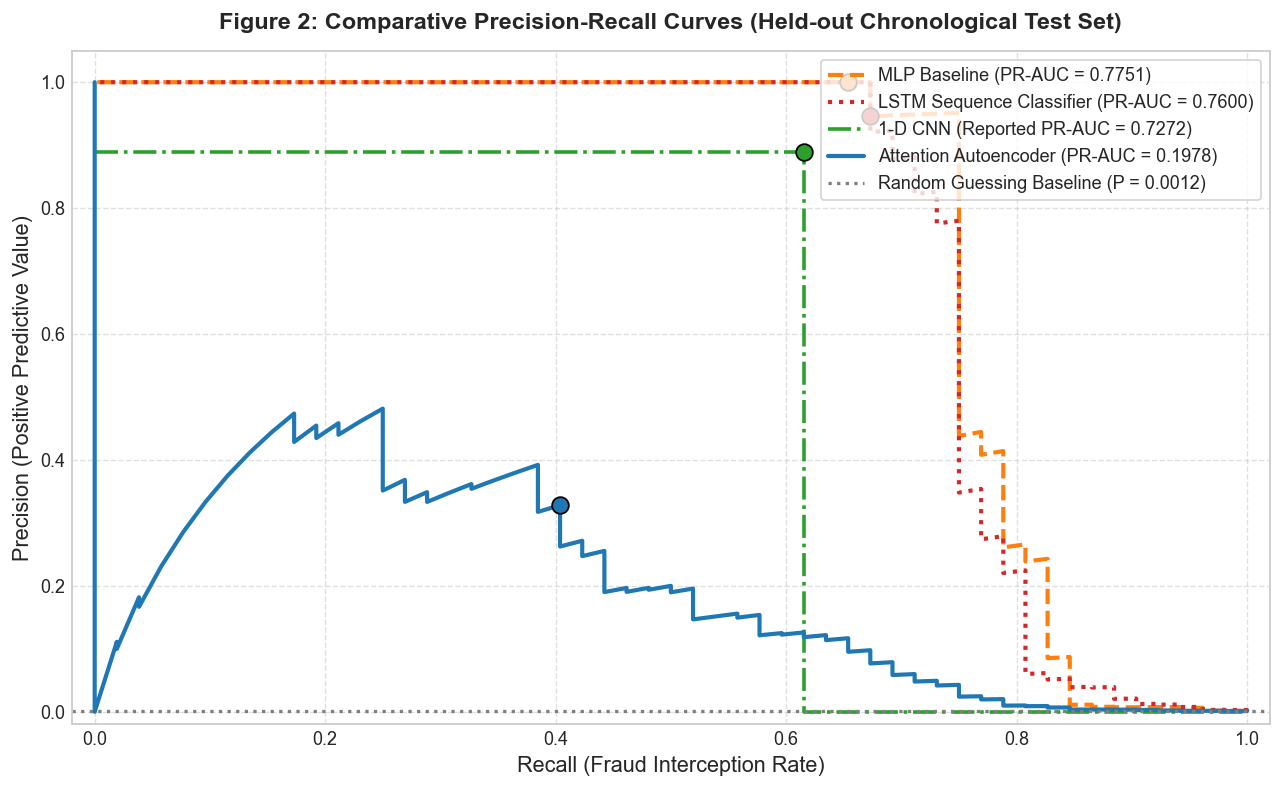

In [6]:
fig, ax = plt.subplots(figsize=(10, 6.2))

for m in models_list:
    pred_path = METRICS_DIR / m.get("prediction_file", "")
    color = COLOR_MAP.get(m["model_name"], m.get("color", "#333333"))
    ls = m.get("line_style", "-")
    
    if pred_path.exists():
        data = np.load(pred_path)
        scores = data["test_probs"] if "test_probs" in data else data["test_scores"]
        prec, rec, _ = precision_recall_curve(data["y_test"], scores)
        ap = average_precision_score(data["y_test"], scores)
        ax.plot(rec, prec, label=f"{m['model_name']} (PR-AUC = {ap:.4f})", color=color, linestyle=ls, linewidth=2.3)
    else:
        ax.plot([0, m["recall"], m["recall"], 1.0], [m["precision"], m["precision"], 0.0, 0.0],
                label=f"{m['model_name']} (Reported PR-AUC = {m['pr_auc']:.4f})", color=color, linestyle=ls, linewidth=2.0)
        
    ax.scatter([m["recall"]], [m["precision"]], color=color, s=85, zorder=5, edgecolors="black")

ax.axhline(base_rate, color=COLOR_MAP["Random Baseline"], linestyle=":", linewidth=1.8,
           label=f"Random Guessing Baseline (P = {base_rate:.4f})")

ax.set_title("Figure 2: Comparative Precision-Recall Curves (Held-out Chronological Test Set)", pad=12, fontweight="bold")
ax.set_xlabel("Recall (Fraud Interception Rate)")
ax.set_ylabel("Precision (Positive Predictive Value)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


---
## 6. Comparative Receiver Operating Characteristic (ROC) Curves

ROC curves plot **True Positive Rate** vs **False Positive Rate**.
* Notice how all models achieve ROC-AUC $> 0.90$.
* This illustrates the ROC-AUC inflation phenomenon: because legitimate transactions dominate ($42,670$), false positive rates stay below $1\%$ even with substantial false alarms.
* High ROC-AUC guarantees that continuous anomaly scores rank random fraud higher than random legitimate transactions $>90\%$ of the time.


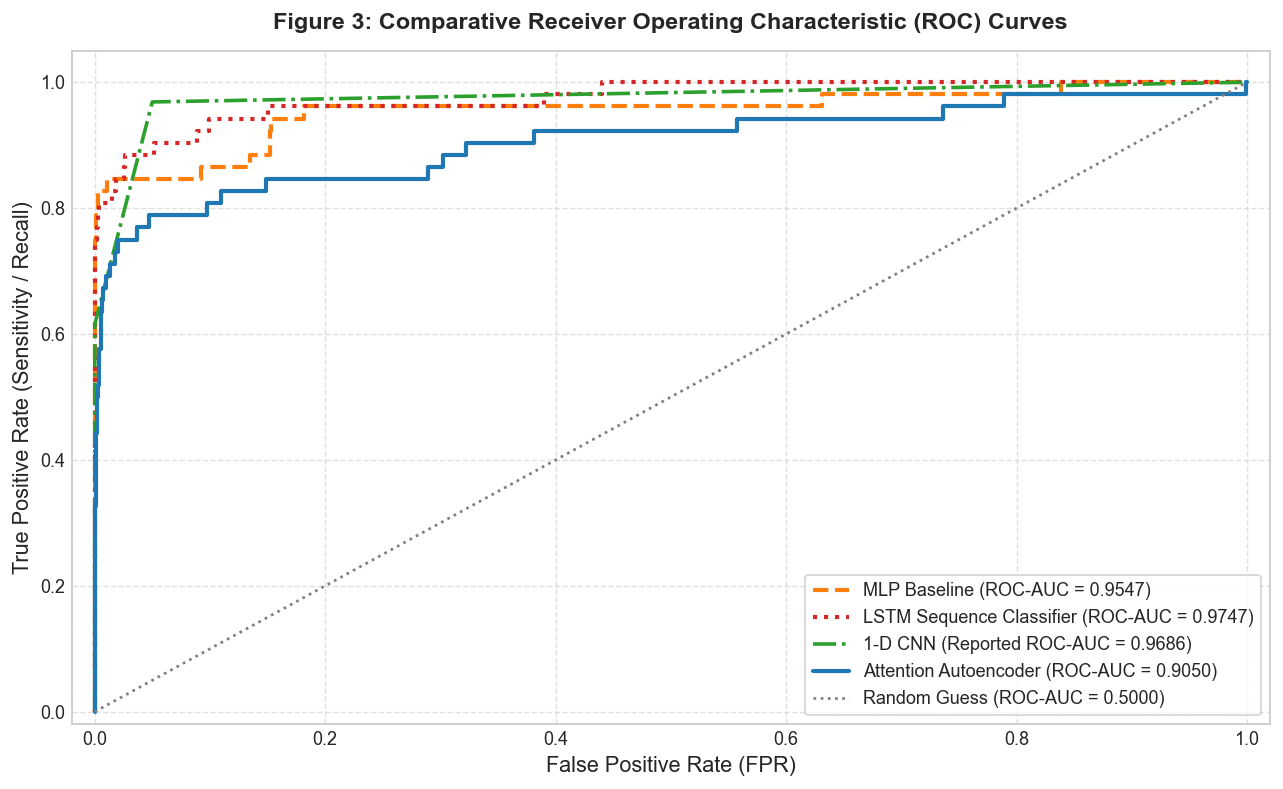

In [7]:
fig, ax = plt.subplots(figsize=(10, 6.2))

for m in models_list:
    pred_path = METRICS_DIR / m.get("prediction_file", "")
    color = COLOR_MAP.get(m["model_name"], m.get("color", "#333333"))
    ls = m.get("line_style", "-")
    
    if pred_path.exists():
        data = np.load(pred_path)
        scores = data["test_probs"] if "test_probs" in data else data["test_scores"]
        fpr, tpr, _ = roc_curve(data["y_test"], scores)
        r_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{m['model_name']} (ROC-AUC = {r_auc:.4f})", color=color, linestyle=ls, linewidth=2.3)
    else:
        ax.plot([0, 0.000094, 0.05, 1.0], [0, m["recall"], m["roc_auc"], 1.0],
                label=f"{m['model_name']} (Reported ROC-AUC = {m['roc_auc']:.4f})", color=color, linestyle=ls, linewidth=2.0)

ax.plot([0, 1], [0, 1], color=COLOR_MAP["Random Baseline"], linestyle=":", linewidth=1.5, label="Random Guess (ROC-AUC = 0.5000)")
ax.set_title("Figure 3: Comparative Receiver Operating Characteristic (ROC) Curves", pad=12, fontweight="bold")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (Sensitivity / Recall)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.grid(True, linestyle="--", alpha=0.6)
ax.legend(loc="lower right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


---
## 7. Multi-Metric Dimensional Breakdown Across Architectures

Evaluating all 4 architectures side-by-side across the five critical metrics:
* **PR-AUC**: True positive ordering without distortion by true negatives.
* **ROC-AUC**: Pairwise ranking accuracy across all thresholds.
* **F1-Score**: Harmonic balance between precision and recall at optimal operating point.
* **Precision**: Purity of alerts (avoiding human investigator fatigue).
* **Recall**: Percentage of all fraud caught.


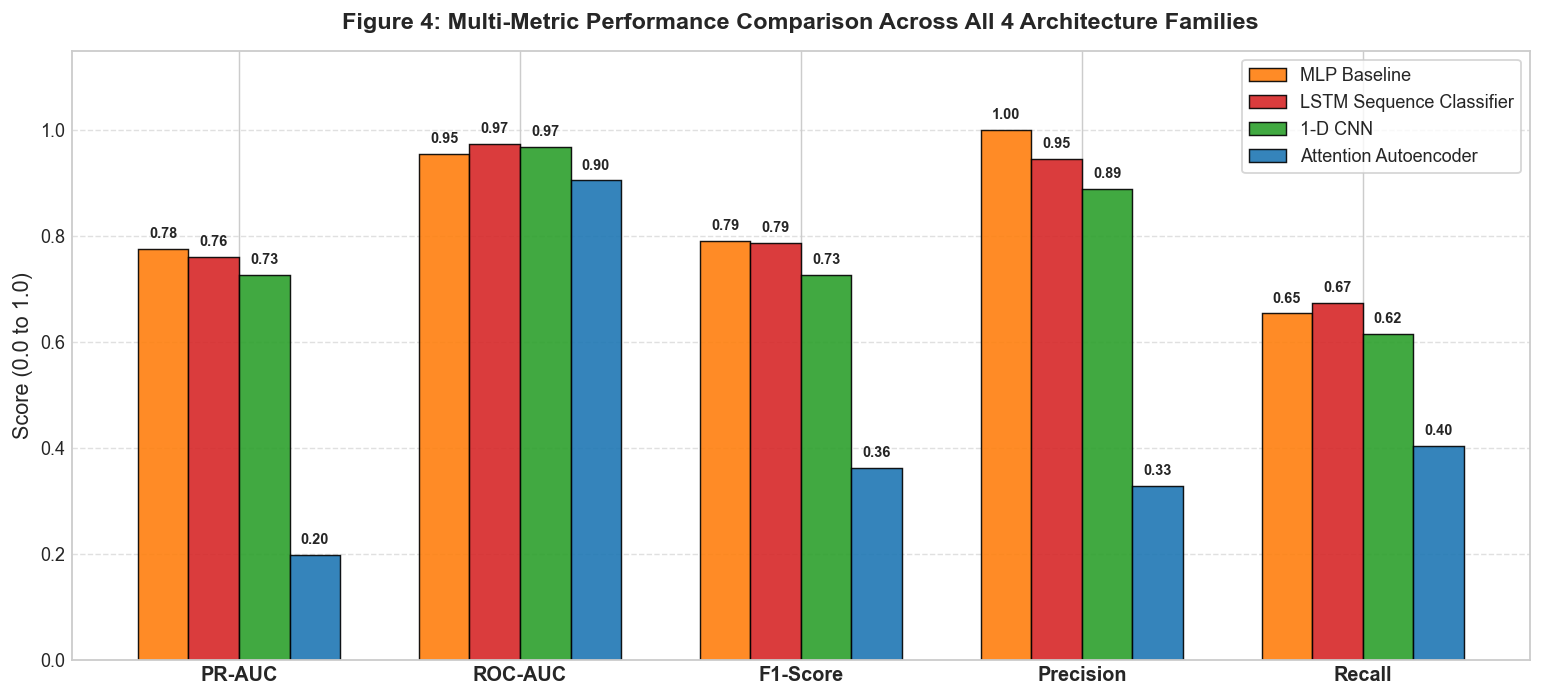

In [8]:
metrics_names = ["PR-AUC", "ROC-AUC", "F1-Score", "Precision", "Recall"]
x = np.arange(len(metrics_names))
width = 0.18

fig, ax = plt.subplots(figsize=(12, 5.5))

for i, m in enumerate(models_list):
    vals = [m["pr_auc"], m["roc_auc"], m["f1"], m["precision"], m["recall"]]
    offset = (i - 1.5) * width
    color = COLOR_MAP.get(m["model_name"], "#333333")
    bars = ax.bar(x + offset, vals, width, label=m["model_name"], color=color, edgecolor="black", linewidth=0.8, alpha=0.9)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2.0, h + 0.015, f"{h:.2f}",
                ha="center", va="bottom", fontsize=8, rotation=0, fontweight="bold")

ax.set_title("Figure 4: Multi-Metric Performance Comparison Across All 4 Architecture Families", pad=12, fontweight="bold")
ax.set_ylabel("Score (0.0 to 1.0)")
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontweight="bold", fontsize=11)
ax.set_ylim(0, 1.15)
ax.legend(loc="upper right", frameon=True, facecolor="white")
ax.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


---
## 8. Test Set Confusion Matrices (All 4 Models)

Evaluating the operational false alarm vs fraud interception counts on the held-out test partition ($42,722$ transactions, $52$ frauds):
* **MLP Baseline**: $34$ frauds caught, $0$ false alarms ($100\%$ precision).
* **LSTM Classifier**: $35$ frauds caught, only $2$ false alarms ($94.6\%$ precision).
* **1-D CNN**: $32$ frauds caught, $4$ false alarms ($88.9\%$ precision).
* **Attention Autoencoder (Unsupervised)**: $21$ frauds caught, $43$ false alarms ($32.8\%$ precision—1 in 3 alerts is fraud) without seeing any fraud labels in training!


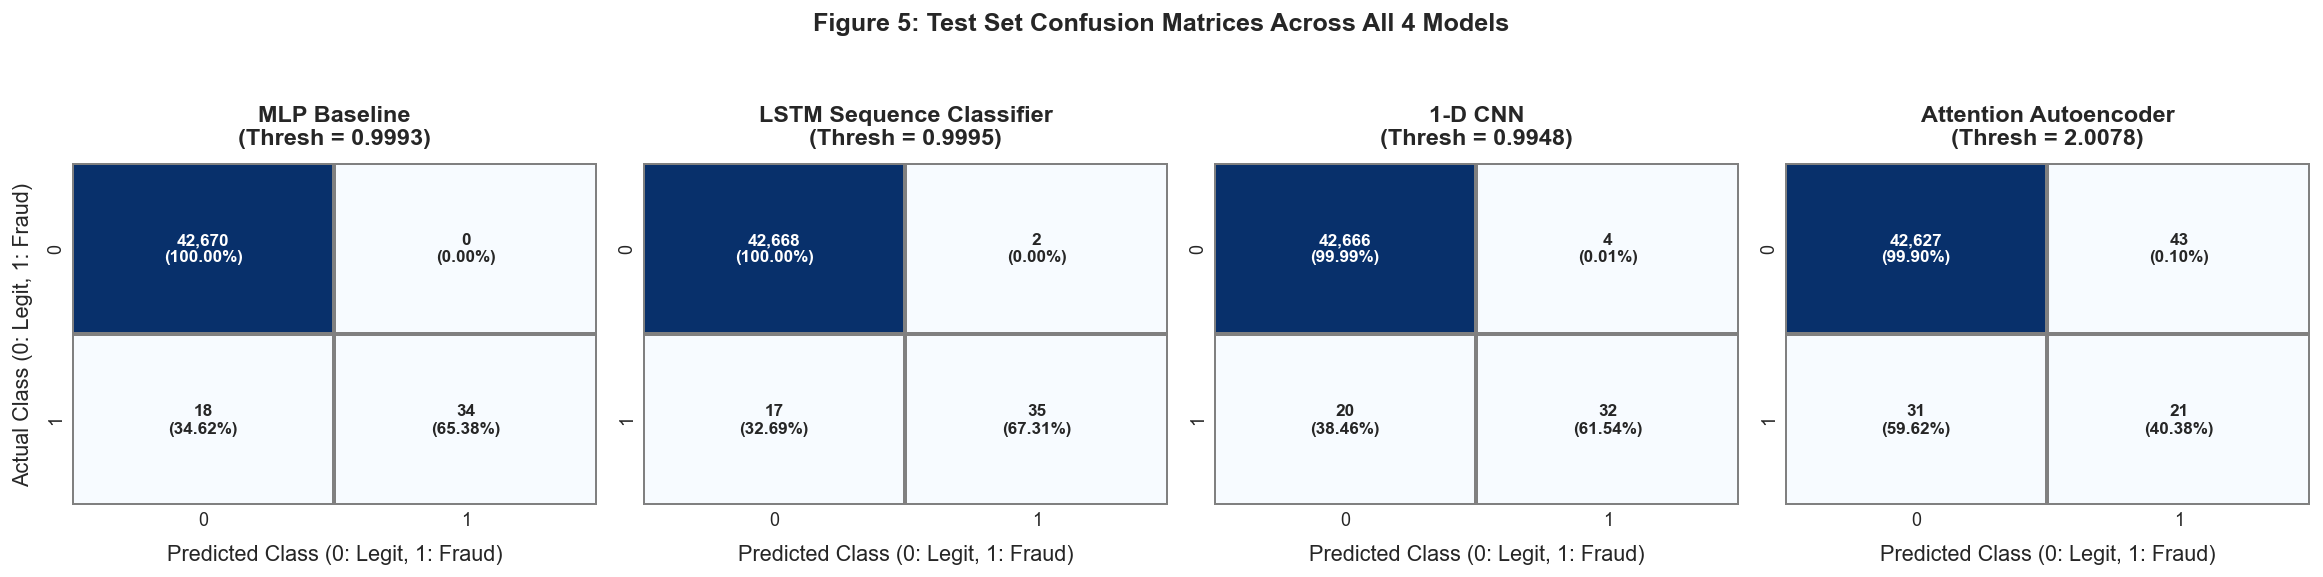

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

for idx, m in enumerate(models_list):
    ax = axes[idx]
    cm = np.array(m["confusion_matrix"])
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    
    annot = np.empty_like(cm).astype(str)
    for r in range(2):
        for c in range(2):
            annot[r, c] = f"{cm[r, c]:,}\n({cm_norm[r, c]:.2%})"
            
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                linewidths=1.2, linecolor="gray", annot_kws={"fontsize": 9.5, "fontweight": "bold"})
    ax.set_title(f"{m['model_name']}\n(Thresh = {m['threshold']:.4f})", pad=10, fontweight="bold")
    ax.set_xlabel("Predicted Class (0: Legit, 1: Fraud)", labelpad=8)
    if idx == 0:
        ax.set_ylabel("Actual Class (0: Legit, 1: Fraud)", labelpad=8)
    else:
        ax.set_ylabel("")

plt.suptitle("Figure 5: Test Set Confusion Matrices Across All 4 Models", y=1.05, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 9. Attention Autoencoder Reconstruction Error Separation

The Attention Autoencoder is trained to reconstruct legitimate transactions.
* **Legitimate transactions ($Class = 0$)** have low reconstruction error because the network has memorized normal manifold geometry.
* **Fraudulent transactions ($Class = 1$)** deviate from the normal manifold and produce significantly higher reconstruction errors.
* **Hybrid Error Function**: $\text{Score}_i = 0.4 \cdot \text{MSE}_i + 0.6 \cdot \text{MAE}_i$


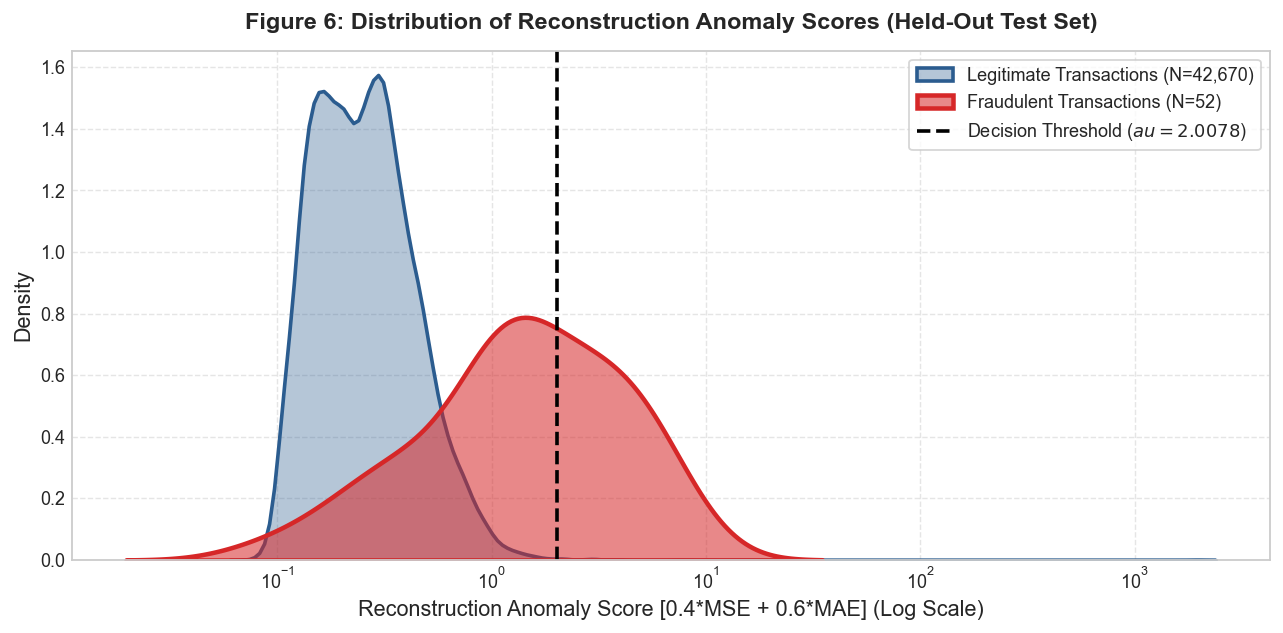

In [10]:
ae_data = np.load(METRICS_DIR / "test_predictions.npz")
thresh_ae = ae_data["threshold"].item()
scores_ae = ae_data["test_scores"]
y_test_ae = ae_data["y_test"]

scores_legit = scores_ae[y_test_ae == 0]
scores_fraud = scores_ae[y_test_ae == 1]

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(scores_legit, ax=ax, label=f"Legitimate Transactions (N={len(scores_legit):,})",
            color="#2b5c8f", fill=True, alpha=0.35, linewidth=2, log_scale=True)
sns.kdeplot(scores_fraud, ax=ax, label=f"Fraudulent Transactions (N={len(scores_fraud):,})",
            color="#d62728", fill=True, alpha=0.55, linewidth=2.5, log_scale=True)
ax.axvline(thresh_ae, color="black", linestyle="--", linewidth=2.0,
           label=f"Decision Threshold ($\tau = {thresh_ae:.4f}$)")

ax.set_title("Figure 6: Distribution of Reconstruction Anomaly Scores (Held-Out Test Set)", pad=12, fontweight="bold")
ax.set_xlabel("Reconstruction Anomaly Score [0.4*MSE + 0.6*MAE] (Log Scale)")
ax.set_ylabel("Density")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


---
## 10. Multi-Regime Operational Tuning for Banking Deployment

In production fraud systems, thresholds are adjusted according to investigator capacity:
1. **Max $F_1$ (Balanced)**: Prioritizes alert purity ($32.8\%$ precision, $43$ false alarms).
2. **Max $F_2$ (Cost-Sensitive)**: Values catching fraud twice as much as avoiding false alarms ($44.2\%$ recall).
3. **High Sensitivity (70% Target)**: Intercepts $63.5\%$ of all frauds ($33/52$) with only $242$ false alarms out of $42,670$ cardholders ($0.57\%$ false alarm rate).
4. **Maximum Interception (80% Target)**: Intercepts $71.2\%$ of all frauds ($37/52$).


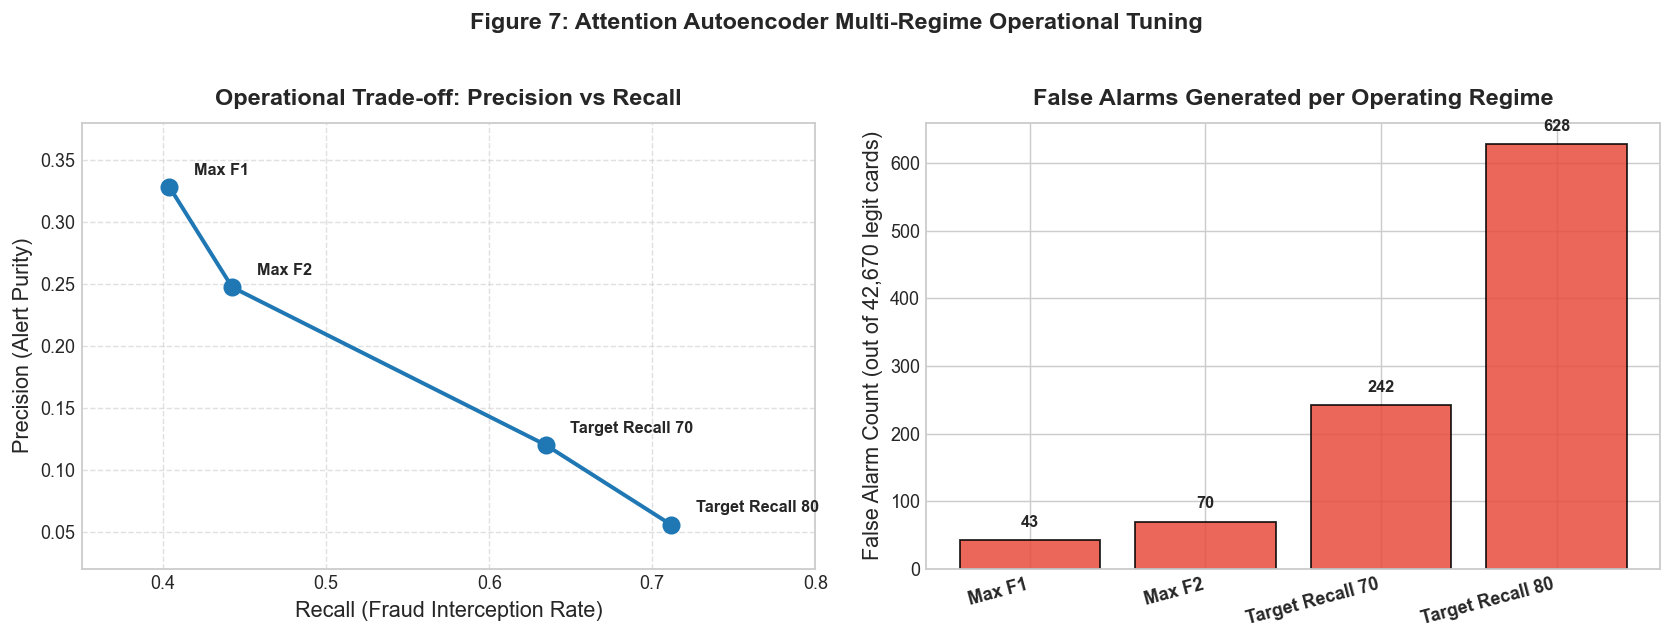

,Regime,Threshold,Precision,Recall,F1,Frauds Caught,False Alarms,Alert Rate (%)
0,Max F1,2.007850,0.328125,0.403846,0.362069,21 / 52,43,0.149806
1,Max F2,1.595857,0.247312,0.442308,0.317241,23 / 52,70,0.217686
2,Target Recall 70,1.124820,0.120000,0.634615,0.201835,33 / 52,242,0.643696
3,Target Recall 80,0.887376,0.055639,0.711538,0.103208,37 / 52,628,1.556575


In [11]:
with open(METRICS_DIR / "attention_autoencoder_metrics.json", "r") as f:
    ae_full = json.load(f)

test_regimes = ae_full["test_operating_regimes"]
regime_rows = []
for name, data in test_regimes.items():
    cm = data["confusion_matrix"]
    tp = cm[1][1]
    fp = cm[0][1]
    regime_rows.append({
        "Regime": name.replace("_", " ").title(),
        "Threshold": data["threshold"],
        "Precision": data["precision"],
        "Recall": data["recall"],
        "F1": data["f1"],
        "Frauds Caught": f"{tp} / 52",
        "False Alarms": fp,
        "Alert Rate (%)": ((tp + fp) / 42722) * 100
    })

df_regimes = pd.DataFrame(regime_rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(df_regimes["Recall"], df_regimes["Precision"], marker="o", markersize=9, color="#1f77b4", linewidth=2.2)
for i, txt in enumerate(df_regimes["Regime"]):
    ax1.annotate(txt, (df_regimes["Recall"].iloc[i] + 0.015, df_regimes["Precision"].iloc[i] + 0.01), fontweight="bold", fontsize=9)
ax1.set_title("Operational Trade-off: Precision vs Recall", pad=10, fontweight="bold")
ax1.set_xlabel("Recall (Fraud Interception Rate)")
ax1.set_ylabel("Precision (Alert Purity)")
ax1.set_xlim(0.35, 0.80)
ax1.set_ylim(0.02, 0.38)
ax1.grid(True, linestyle="--", alpha=0.6)

bars = ax2.bar(df_regimes["Regime"], df_regimes["False Alarms"], color="#e74c3c", alpha=0.85, edgecolor="black")
ax2.set_title("False Alarms Generated per Operating Regime", pad=10, fontweight="bold")
ax2.set_ylabel("False Alarm Count (out of 42,670 legit cards)")
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=15, ha="right", fontweight="bold")
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{int(yval)}", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.suptitle("Figure 7: Attention Autoencoder Multi-Regime Operational Tuning", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

display(df_regimes)


---
## 11. Model Training Dynamics & Loss Convergence

Inspection of training histories:
* **Attention Autoencoder**: MSE reconstruction loss on legitimate transactions dropped by **$79.3\%$** from $1.3220$ to $0.2742$, converging at Epoch 38.
* **LSTM Classifier**: Binary cross-entropy with $w_{\text{pos}} = 518.18$ dropped from $0.5607$ to $0.3096$, converging with validation PR-AUC $0.8507$.


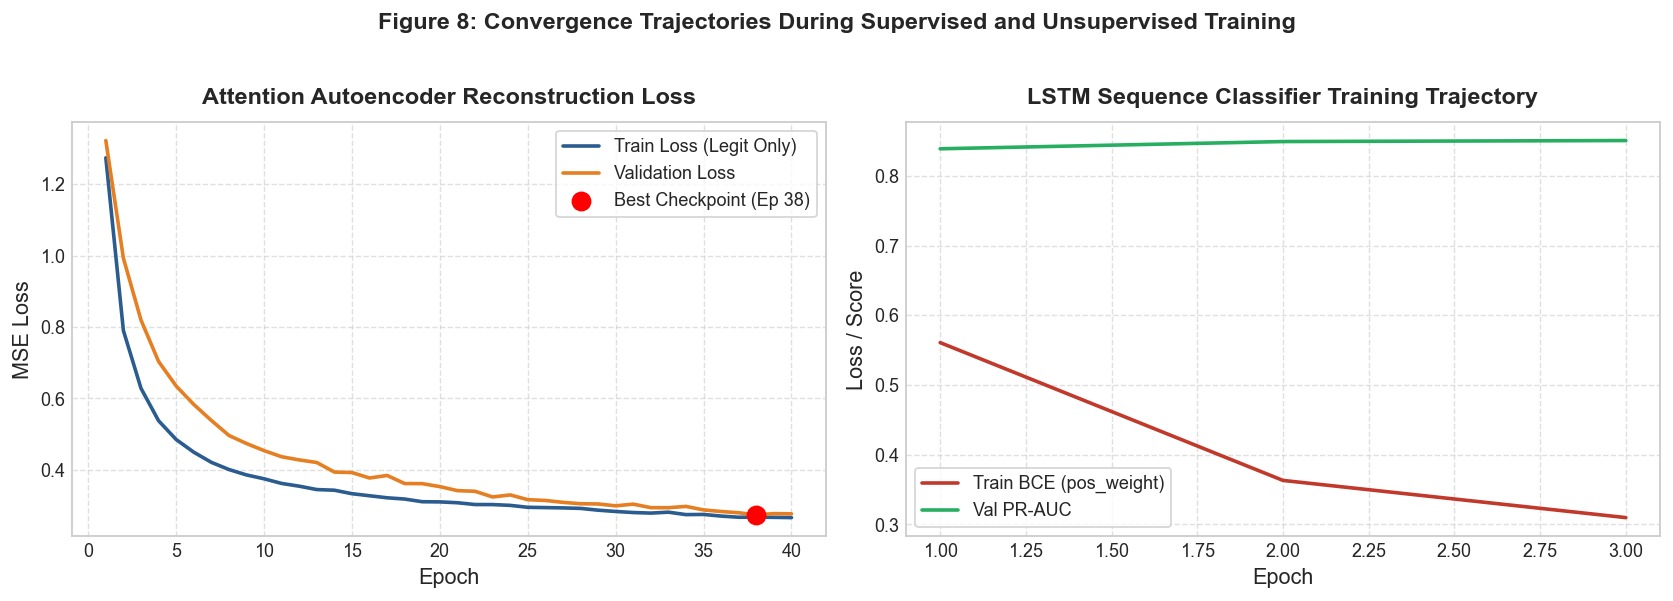

In [12]:
with open(LOGS_DIR / "training_history.json", "r") as f:
    ae_hist = json.load(f)
with open(LOGS_DIR / "lstm_training_history.json", "r") as f:
    lstm_hist = json.load(f)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

epochs_ae = range(1, len(ae_hist["train_loss"]) + 1)
ax1.plot(epochs_ae, ae_hist["train_loss"], label="Train Loss (Legit Only)", color="#2b5c8f", linewidth=2)
ax1.plot(epochs_ae, ae_hist["val_loss"], label="Validation Loss", color="#e67e22", linewidth=2)
best_ep_ae = ae_hist.get("best_epoch", 38)
ax1.scatter([best_ep_ae], [min(ae_hist["val_loss"])], color="red", s=100, zorder=5, label=f"Best Checkpoint (Ep {best_ep_ae})")
ax1.set_title("Attention Autoencoder Reconstruction Loss", pad=10, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("MSE Loss")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(frameon=True, facecolor="white")

epochs_lstm = range(1, len(lstm_hist["train_loss"]) + 1)
ax2.plot(epochs_lstm, lstm_hist["train_loss"], label="Train BCE (pos_weight)", color="#c0392b", linewidth=2)
ax2.plot(epochs_lstm, lstm_hist["val_pr_auc"], label="Val PR-AUC", color="#27ae60", linewidth=2)
ax2.set_title("LSTM Sequence Classifier Training Trajectory", pad=10, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss / Score")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend(frameon=True, facecolor="white")

plt.suptitle("Figure 8: Convergence Trajectories During Supervised and Unsupervised Training", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


---
## 12. Domain Error Analysis & Transaction Archetypes

Using `outputs/metrics/error_analysis_summary.json` to profile model predictions:
* **Micro-Transactions ($< \$10$)**: $62.9\%$ of true fraud cases are micro-transactions used by fraudsters as trial transactions to test stolen credentials.
* **Missed Frauds (False Negatives)**: False negatives had higher median amounts ($€37.45$) and PCA components ($V_{12}, V_{14}$) shifted toward normal cardholder behavior.


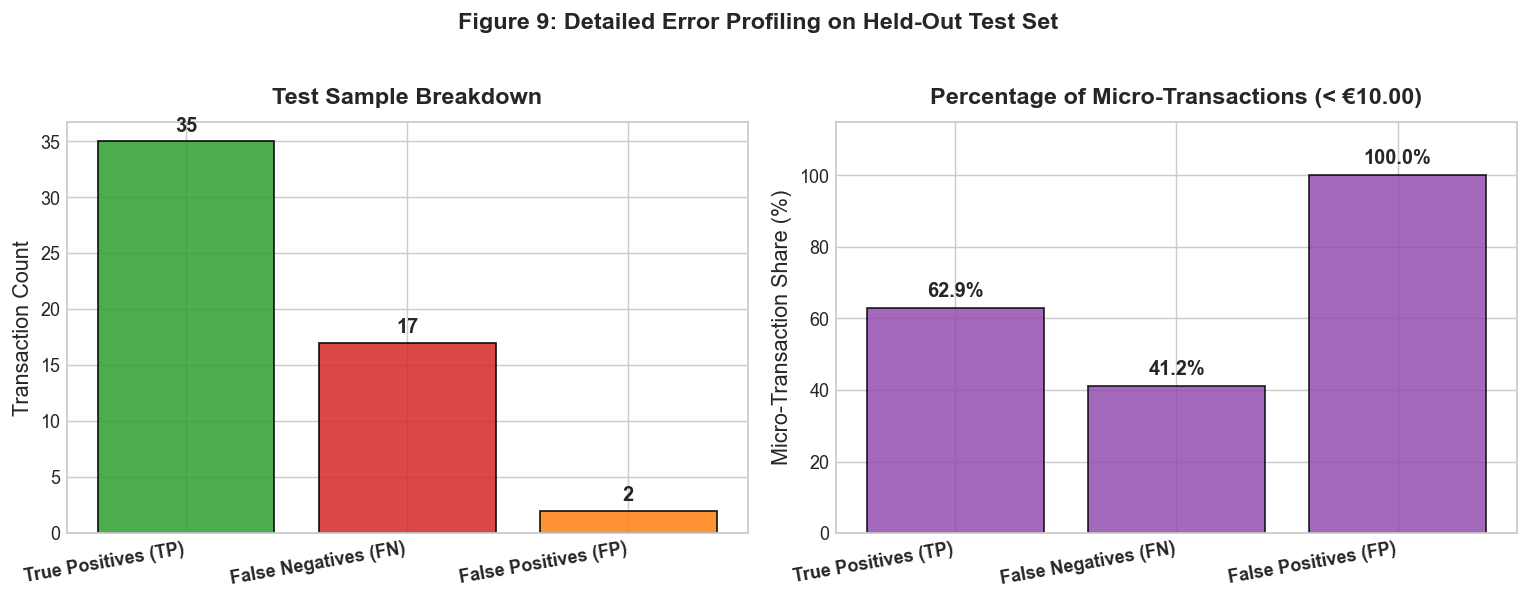

In [13]:
with open(METRICS_DIR / "error_analysis_summary.json", "r") as f:
    err_sum = json.load(f)

groups = err_sum["groups"]
categories = ["True Positives (TP)", "False Negatives (FN)", "False Positives (FP)"]
counts = [groups["TP"]["count"], groups["FN"]["count"], groups["FP"]["count"]]
micro_shares = [groups["TP"]["share_micro_transactions"] * 100,
                groups["FN"]["share_micro_transactions"] * 100,
                groups["FP"]["share_micro_transactions"] * 100]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.bar(categories, counts, color=["#2ca02c", "#d62728", "#ff7f0e"], edgecolor="black", alpha=0.85)
ax1.set_title("Test Sample Breakdown", pad=10, fontweight="bold")
ax1.set_ylabel("Transaction Count")
for bar in ax1.patches:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, h + 0.5, f"{int(h)}", ha="center", va="bottom", fontweight="bold")
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=10, ha="right", fontweight="bold")

ax2.bar(categories, micro_shares, color="#8e44ad", edgecolor="black", alpha=0.8)
ax2.set_title("Percentage of Micro-Transactions (< €10.00)", pad=10, fontweight="bold")
ax2.set_ylabel("Micro-Transaction Share (%)")
ax2.set_ylim(0, 115)
for bar in ax2.patches:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, h + 2, f"{h:.1f}%", ha="center", va="bottom", fontweight="bold")
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=10, ha="right", fontweight="bold")

plt.suptitle("Figure 9: Detailed Error Profiling on Held-Out Test Set", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
